# v3 · 02 Development walk-forward (2013–2022) and freeze (design note §5.2–5.3)

Six candidates are run through a yearly walk-forward over 2013–2022 and backtested with $100,000, after costs, with cash earning the lagged T-bill rate: three probability treatments (C1 no class weights, C2 prior correction, C3 sigmoid calibration), each with a default-long and a default-cash rule. v2 as it was (C0) and Buy & Hold are shown as references; neither can be picked.

**Selection rule (fixed in advance):** highest Sharpe over T-bills; ties → fewer round trips. The pick goes forward even if it does not beat Buy & Hold.

**Caveat (calibration report):** no candidate passed the §5.1 calibration rule. Per design note §6, trading results are reported but are not a test of calibration.

**Nothing after 2022-12-31 is scored here.** The configuration is frozen at the end and committed before any 2023+ row is used.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, v2, v3
from src.data import load_snapshot
from src.dataset import build_dataset_v2

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
OUT = config.OUTPUT_DIR / "v3"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

raw = load_snapshot()
assert raw.index.max() <= pd.Timestamp("2026-10-12"), "no post-holdout data may be loaded before the freeze"
prices = raw[["Open", "Close"]]
ds = build_dataset_v2(raw)
rf = v2.load_tbill_daily(raw.index)
params = v3.v2_params()
DEV = list(range(2013, 2023))
days = ds.loc["2013-01-01":"2022-12-31"].index
rf_d = rf.loc[days]
print(f"development days {days.min().date()} → {days.max().date()} ({len(days)})")

development days 2013-01-02 → 2022-12-30 (2518)


## 1. Walk-forward and backtests

In [2]:
rows, RUNS = [], {}
for kind in v3.CANDIDATES:
    wf = v3.walk_forward_proba(ds, kind, DEV, params)
    er = v3.expected_return(wf)
    for default in v2.DEFAULTS:
        pos = v2.positions_from_er(er, default)
        held = v2.held_from_positions(pos, start=1 if default == "long" else 0)
        sim = v2.simulate(held, prices.loc[days], rf_d)
        cid = f"{kind}-{default[0].upper()}"
        RUNS[cid] = (er, held, sim)
        rows.append({"id": cid, "treatment": kind, "default": default, "eligible": kind != "C0",
                     **v2.summarize(sim, held, rf_d, cid)})
bh_held = v2.buy_and_hold_held(days)
bh_sim = v2.simulate(bh_held, prices.loc[days], rf_d)
bh = v2.summarize(bh_sim, bh_held, rf_d, "S0 Buy & Hold")
dev = pd.DataFrame(rows).drop(columns="strategy").set_index("id")
display(dev.sort_values("sharpe_excess", ascending=False))
print("Buy & Hold:", {k: bh[k] for k in ["final_value", "sharpe_excess", "max_drawdown", "exposure"]})

,treatment,default,eligible,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
id,,,,,,,,,,,,
C3-L,C3,long,True,316843.5800,2.1684,0.1223,0.1737,0.7080,-0.3372,1,1.0000,99.9000
C2-L,C2,long,True,245504.3900,1.4550,0.0940,0.1667,0.5780,-0.3372,22,0.9530,6534.1600
C1-L,C1,long,True,249244.3800,1.4924,0.0957,0.1707,0.5770,-0.3372,23,0.9500,6272.5900
C3-C,C3,cash,True,207355.2200,1.0736,0.0757,0.1572,0.4950,-0.3372,32,0.7010,8738.1400
C0-L,C0,long,False,135210.6600,0.3521,0.0307,0.1194,0.2490,-0.2235,94,0.6040,21413.2400
C1-C,C1,cash,True,120871.4600,0.2087,0.0192,0.1351,0.1520,-0.2419,79,0.6120,17193.5800
C2-C,C2,cash,True,118843.8600,0.1884,0.0174,0.1327,0.1390,-0.2631,80,0.6200,18389.4100
C0-C,C0,cash,False,78027.6900,-0.2197,-0.0245,0.0575,-0.5360,-0.3226,61,0.1510,10719.7400


Buy & Hold: {'final_value': 316843.58, 'sharpe_excess': 0.708, 'max_drawdown': -0.3372, 'exposure': 1.0}


## 2. Apply the selection rule

In [3]:
elig = dev[dev["eligible"]].sort_values(["sharpe_excess", "round_trips"], ascending=[False, True])
PICK = elig.index[0]
print(f"Selected: {PICK} | Sharpe over T-bills {elig.loc[PICK, 'sharpe_excess']:.3f} vs Buy & Hold {bh['sharpe_excess']:.3f}"
      f" | beats Buy & Hold's Sharpe: {bool(elig.loc[PICK, 'sharpe_excess'] > bh['sharpe_excess'])}")
elig[["sharpe_excess", "round_trips", "final_value", "exposure", "max_drawdown"]]

Selected: C3-L | Sharpe over T-bills 0.708 vs Buy & Hold 0.708 | beats Buy & Hold's Sharpe: False


,sharpe_excess,round_trips,final_value,exposure,max_drawdown
id,,,,,
C3-L,0.7080,1,316843.5800,1.0000,-0.3372
C2-L,0.5780,22,245504.3900,0.9530,-0.3372
C1-L,0.5770,23,249244.3800,0.9500,-0.3372
C3-C,0.4950,32,207355.2200,0.7010,-0.3372
C1-C,0.1520,79,120871.4600,0.6120,-0.2419
C2-C,0.1390,80,118843.8600,0.6200,-0.2631


## 3. Year by year, and the $100,000 paths

,C0-L,C0-C,C1-L,C1-C,C2-L,C2-C,C3-L,C3-C,Buy & Hold
Date,,,,,,,,,
2013,0.2000,-1.7000,12.7000,-2.7000,19.4000,-4.0000,29.0000,2.0000,29.0000
2014,7.4000,-8.2000,14.3000,2.8000,14.2000,8.8000,14.6000,5.3000,14.6000
2015,-8.3000,-11.9000,-1.4000,-1.5000,-1.4000,2.9000,1.3000,-0.4000,1.3000
2016,15.1000,-3.2000,13.4000,7.7000,13.0000,14.4000,13.6000,4.5000,13.6000
2017,6.2000,0.9000,16.4000,0.8000,16.3000,1.3000,20.8000,20.8000,20.8000
2018,-14.4000,-2.2000,-5.2000,-8.6000,-5.5000,-12.9000,-5.2000,5.9000,-5.2000
2019,23.6000,-6.2000,31.1000,27.0000,31.2000,17.9000,31.1000,17.4000,31.1000
2020,-11.7000,7.8000,9.7000,-4.2000,1.0000,-8.1000,17.2000,16.6000,17.2000
2021,14.1000,0.0000,30.6000,20.4000,33.1000,27.5000,30.5000,33.4000,30.5000


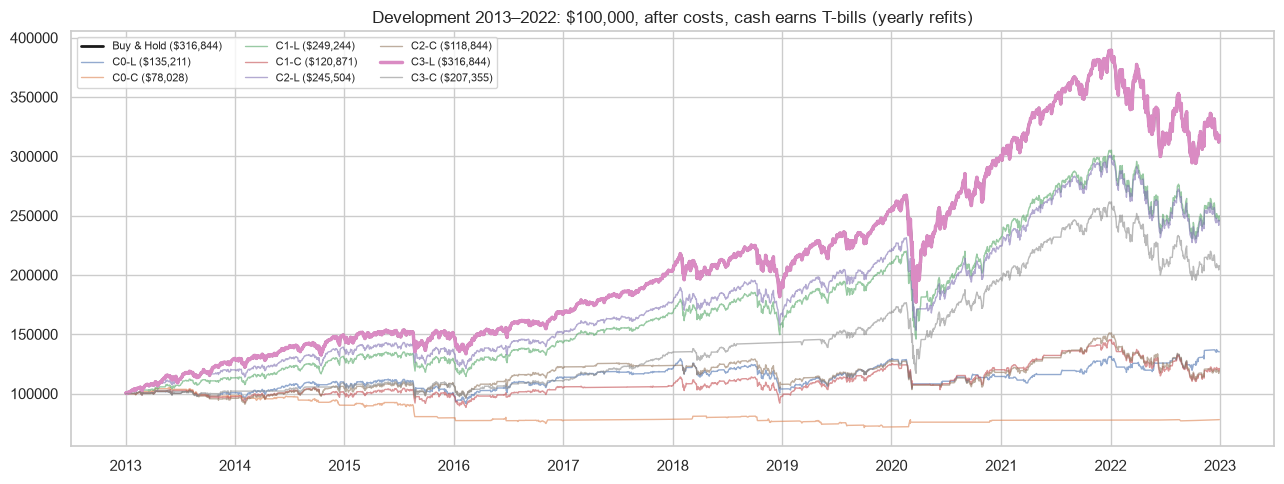

In [4]:
vals = pd.DataFrame({cid: RUNS[cid][2]["value"] for cid in dev.index} | {"Buy & Hold": bh_sim["value"]})
yearly = vals.groupby(vals.index.year).apply(lambda g: g.iloc[-1] / g.iloc[0] - 1)
display((yearly * 100).round(1))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(bh_sim["value"], color="k", lw=2, label=f"Buy & Hold (${bh['final_value']:,.0f})")
for cid in dev.index:
    lw, alpha = (2.5, 1) if cid == PICK else (1, 0.6)
    ax.plot(RUNS[cid][2]["value"], lw=lw, alpha=alpha, label=f"{cid} (${dev.loc[cid, 'final_value']:,.0f})")
ax.set_title("Development 2013–2022: $100,000, after costs, cash earns T-bills (yearly refits)")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); savefig("dev_paths"); plt.show()

## 4. Freeze

In [5]:
kind, default = PICK.split("-")[0], dev.loc[PICK, "default"]
FROZEN = {
    "candidate": PICK, "treatment": kind, "default": default, "model": "HGB",
    "params": params, "label": "±1% open(t+1)→open(t+6)", "gap": config.V2_GAP, "hurdle": v2.ROUND_TRIP,
    "refit": "every January on labelled rows from 2006 whose labels end before the year (last 6 rows dropped)",
    "dev_sharpe_excess": float(dev.loc[PICK, "sharpe_excess"]), "dev_final_value": float(dev.loc[PICK, "final_value"]),
    "dev_bh_sharpe_excess": bh["sharpe_excess"], "dev_bh_final_value": bh["final_value"],
    "calibration_passed": False,
    "design_note_sha256": (config.ROOT / "docs" / "v3_design_note.sha256").read_text().split()[0],
    "frozen_before_any_2023_row_scored": True,
}
(OUT / "frozen_config.json").write_text(json.dumps(FROZEN, indent=2, default=str))
res = {"development": json.loads(dev.to_json(orient="index")), "buy_and_hold": bh,
       "yearly_returns": json.loads(yearly.round(5).to_json(orient="index")), "pick": PICK}
(OUT / "development.json").write_text(json.dumps(res, indent=2, default=str))
FROZEN

{'candidate': 'C3-L',
 'treatment': 'C3',
 'default': 'long',
 'model': 'HGB',
 'params': {'clf__l2_regularization': 0.17336465350777208,
  'clf__learning_rate': 0.032268708256236636,
  'clf__max_depth': 3,
  'clf__max_iter': 51,
  'clf__min_samples_leaf': 153},
 'label': '±1% open(t+1)→open(t+6)',
 'gap': 6,
 'hurdle': 0.003,
 'refit': 'every January on labelled rows from 2006 whose labels end before the year (last 6 rows dropped)',
 'dev_sharpe_excess': 0.708,
 'dev_final_value': 316843.58,
 'dev_bh_sharpe_excess': 0.708,
 'dev_bh_final_value': 316843.58,
 'calibration_passed': False,
 'design_note_sha256': '8149938bb8fcd9d471f17d406da2c0170fb9f473d1459ce296a57a162d939fb0',
 'frozen_before_any_2023_row_scored': True}